# Task 6: Principal Component Analysis (PCA)

**Dataset:** `store_sales_dataset.csv`

We reduce the dimensionality of the data with **PCA**:

1. PCA **from scratch** (covariance matrix + eigen decomposition with NumPy)
2. PCA with **scikit-learn** (to verify the manual result)

We then look at the explained variance, component loadings, reconstruction error
and a 2D projection of the data.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%matplotlib inline

## 2. Load data

In [2]:
df = pd.read_csv("store_sales_dataset.csv")
print(f"Dataset size: {len(df)} rows")
df.head()

Dataset size: 500 rows


,Order_ID,Product,Category,City,Quantity,Unit_Price,Total_Sales
0,101,Smartphone,Electronics,Hyderabad,5,12450,62250
1,102,USB Cable,Accessories,Delhi,2,4550,9100
2,103,Television,Electronics,Mumbai,38,11800,448400
3,104,Power Bank,Accessories,Hyderabad,12,6750,81000
4,105,Webcam,Accessories,Bangalore,34,2950,100300


## 3. Prepare features (numerical columns + one-hot encoded City)

In [3]:
numeric_features = ["Quantity", "Unit_Price", "Total_Sales"]
X = pd.concat(
    [df[numeric_features], pd.get_dummies(df["City"], prefix="City", dtype=float)],
    axis=1,
)
feature_names = list(X.columns)

print(f"Features used ({len(feature_names)}):")
for name in feature_names:
    print(f"  {name}")

Features used (8):
  Quantity
  Unit_Price
  Total_Sales
  City_Bangalore
  City_Chennai
  City_Delhi
  City_Hyderabad
  City_Mumbai


## 4. Standardize the data (PCA is sensitive to scale)

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Data standardized (mean = 0, std = 1).")

Data standardized (mean = 0, std = 1).


## 5. PCA from scratch (Covariance matrix + Eigen decomposition)

### Covariance matrix

In [5]:
cov_matrix = np.cov(X_scaled, rowvar=False)
pd.DataFrame(cov_matrix, index=feature_names, columns=feature_names).round(3)

,Quantity,Unit_Price,Total_Sales,City_Bangalore,City_Chennai,City_Delhi,City_Hyderabad,City_Mumbai
Quantity,1.002,-0.008,0.637,-0.041,-0.017,0.038,-0.023,0.034
Unit_Price,-0.008,1.002,0.679,0.146,0.022,-0.042,-0.025,-0.080
Total_Sales,0.637,0.679,1.002,0.080,-0.005,-0.005,-0.026,-0.035
City_Bangalore,-0.041,0.146,0.080,1.002,-0.216,-0.224,-0.203,-0.242
City_Chennai,-0.017,0.022,-0.005,-0.216,1.002,-0.266,-0.241,-0.287
City_Delhi,0.038,-0.042,-0.005,-0.224,-0.266,1.002,-0.250,-0.297
City_Hyderabad,-0.023,-0.025,-0.026,-0.203,-0.241,-0.250,1.002,-0.269
City_Mumbai,0.034,-0.080,-0.035,-0.242,-0.287,-0.297,-0.269,1.002


### Eigenvalues and explained variance

In [6]:
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
# One-hot City columns always sum to 1, so one eigenvalue is ~0 (tiny negatives from rounding)
eigenvalues = np.clip(eigenvalues, 0, None)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

explained_ratio = eigenvalues / eigenvalues.sum()
cumulative_ratio = np.cumsum(explained_ratio)

pc_names = [f"PC{i + 1}" for i in range(len(eigenvalues))]

print(f"  {'PC':<5} {'Eigenvalue':>12} {'Explained':>12} {'Cumulative':>12}")
for name, ev, ratio, cum in zip(pc_names, eigenvalues, explained_ratio, cumulative_ratio):
    print(f"  {name:<5} {ev:>12.4f} {ratio:>12.4f} {cum:>12.4f}")

n_components = int(np.searchsorted(cumulative_ratio, 0.90) + 1)
print(f"\nComponents needed to keep at least 90% variance: {n_components}")

X_pca_manual = X_scaled @ eigenvectors[:, :n_components]

  PC      Eigenvalue    Explained   Cumulative
  PC1         1.9521       0.2435       0.2435
  PC2         1.3291       0.1658       0.4093
  PC3         1.2889       0.1608       0.5701
  PC4         1.2435       0.1551       0.7252
  PC5         1.2178       0.1519       0.8772
  PC6         0.9176       0.1145       0.9916
  PC7         0.0670       0.0084       1.0000
  PC8         0.0000       0.0000       1.0000

Components needed to keep at least 90% variance: 6


### Graph: Scree plot (explained variance)

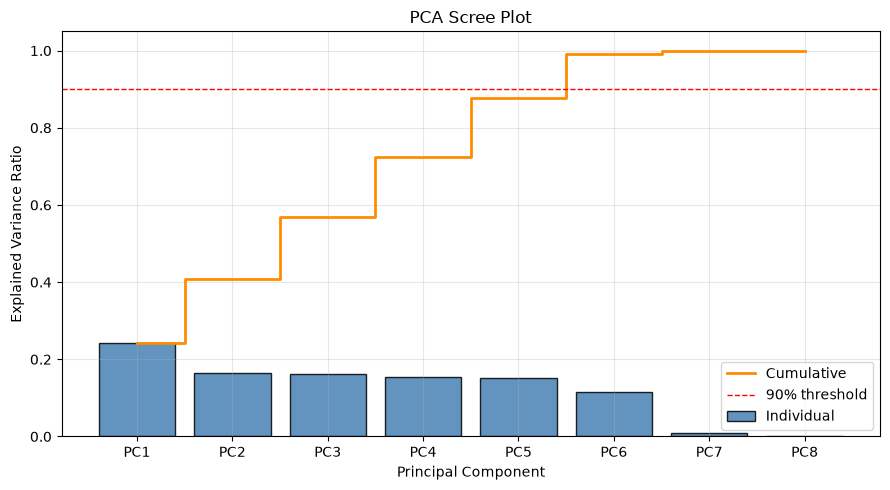

In [7]:
x_pos = np.arange(1, len(eigenvalues) + 1)
plt.figure(figsize=(9, 5))
plt.bar(
    x_pos,
    explained_ratio,
    color="steelblue",
    edgecolor="black",
    alpha=0.85,
    label="Individual",
)
plt.step(
    x_pos,
    cumulative_ratio,
    where="mid",
    color="darkorange",
    linewidth=2,
    label="Cumulative",
)
plt.axhline(0.90, color="red", linestyle="--", linewidth=1, label="90% threshold")
plt.xticks(x_pos, pc_names)
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. PCA using scikit-learn (verification)

In [8]:
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:")
for name, ratio in zip(pc_names, pca.explained_variance_ratio_):
    print(f"  {name}: {ratio:.4f}")
print(f"Total variance retained: {pca.explained_variance_ratio_.sum():.4f}")

# Eigenvector signs are arbitrary, so compare absolute values
match = np.allclose(np.abs(X_pca), np.abs(X_pca_manual), atol=1e-6)
print(f"\nManual PCA matches scikit-learn PCA: {match}")

Explained variance ratio:
  PC1: 0.2435
  PC2: 0.1658
  PC3: 0.1608
  PC4: 0.1551
  PC5: 0.1519
  PC6: 0.1145
Total variance retained: 0.9916

Manual PCA matches scikit-learn PCA: True


### Principal component loadings (feature contribution)

In [9]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_names,
    columns=pc_names[:n_components],
)

print("Top contributing feature for each component:")
for pc in loadings.columns:
    top = loadings[pc].abs().idxmax()
    print(f"  {pc}: {top} ({loadings.loc[top, pc]:.4f})")

loadings.round(4)

Top contributing feature for each component:
  PC1: Total_Sales (0.6970)
  PC2: City_Mumbai (0.7501)
  PC3: City_Delhi (0.8456)
  PC4: City_Chennai (0.7488)
  PC5: City_Hyderabad (0.6748)
  PC6: Unit_Price (0.6238)


,PC1,PC2,PC3,PC4,PC5,PC6
Quantity,0.4545,0.3193,0.1461,0.0979,0.2451,-0.6041
Unit_Price,0.5253,-0.1927,-0.1218,-0.0639,-0.1101,0.6238
Total_Sales,0.6970,0.0795,0.0124,0.0105,0.0906,0.0411
City_Bangalore,0.1513,-0.3340,-0.2287,-0.3291,-0.6063,-0.4166
City_Chennai,0.0044,-0.3725,-0.2205,0.7488,0.2142,-0.0429
City_Delhi,-0.0076,0.0606,0.8456,0.0656,-0.1938,0.1628
City_Hyderabad,-0.0535,-0.1949,-0.0324,-0.5592,0.6748,0.0361
City_Mumbai,-0.0760,0.7501,-0.3829,0.0156,-0.1148,0.2024


### Graph: loadings heatmap

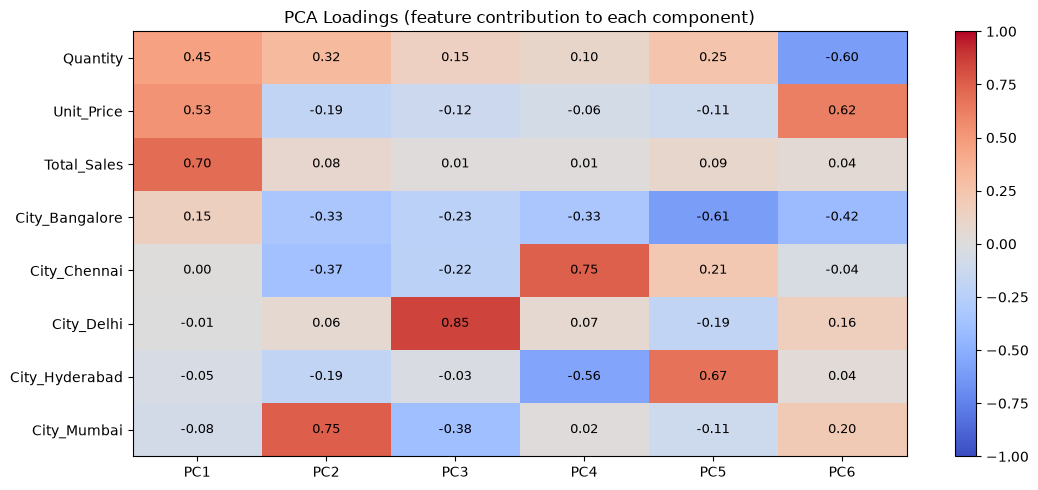

In [10]:
fig, ax = plt.subplots(figsize=(1.2 * n_components + 4, 5))
im = ax.imshow(loadings.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(n_components), loadings.columns)
ax.set_yticks(range(len(feature_names)), feature_names)
for i in range(len(feature_names)):
    for j in range(n_components):
        ax.text(j, i, f"{loadings.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax)
ax.set_title("PCA Loadings (feature contribution to each component)")
plt.tight_layout()
plt.show()

## 7. Transformed data and reconstruction error

In [11]:
print(f"Original shape:    {X_scaled.shape}")
print(f"Transformed shape: {X_pca.shape}")

X_reconstructed = pca.inverse_transform(X_pca)
recon_error = np.mean((X_scaled - X_reconstructed) ** 2)
print(f"Reconstruction error (MSE, standardized units): {recon_error:.4f}")

pca_df = pd.DataFrame(np.round(X_pca, 4), columns=pc_names[:n_components])
pca_df.insert(0, "Category", df["Category"].values)
print("\nTransformed data (first 10 rows):")
pca_df.head(10)

Original shape:    (500, 8)
Transformed shape: (500, 6)
Reconstruction error (MSE, standardized units): 0.0084

Transformed data (first 10 rows):


,Category,PC1,PC2,PC3,PC4,PC5,PC6
0,Electronics,-1.3576,-1.0838,-0.3196,-1.6158,1.2939,0.9687
1,Accessories,-2.1705,-0.3079,1.9228,0.0347,-0.8754,0.6723
2,Electronics,1.1950,2.2766,-0.6654,0.1773,0.1851,-0.4111
3,Accessories,-1.4661,-0.7105,-0.1219,-1.4985,1.5503,0.0552
4,Accessories,-0.2568,-0.3890,-0.3143,-0.7374,-1.3189,-2.7321
5,Electronics,1.3054,1.1653,-1.2452,-0.1713,-0.5882,2.2396
6,Electronics,-1.3582,1.1010,-1.1676,-0.1581,-0.7626,1.5238
7,Accessories,-0.9382,0.1213,2.0936,0.1567,-0.5154,0.0626
8,Accessories,-1.0876,-0.3659,0.0407,-1.3937,1.8098,-0.6329
9,Electronics,0.8168,-1.0160,-0.6832,-0.9517,-1.7052,-0.9063


## 8. Graph: data projected onto PC1 and PC2

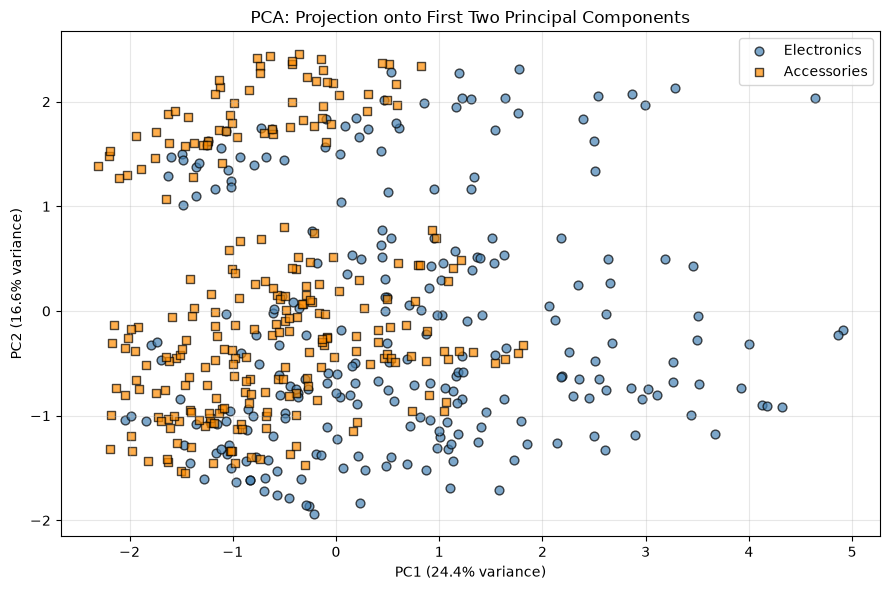

In [12]:
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
styles = {
    "Electronics": {"color": "steelblue", "marker": "o"},
    "Accessories": {"color": "darkorange", "marker": "s"},
}
for category, style in styles.items():
    mask = (df["Category"] == category).values
    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=category,
        color=style["color"],
        marker=style["marker"],
        edgecolor="black",
        s=40,
        alpha=0.7,
    )
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0] * 100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1] * 100:.1f}% variance)")
plt.title("PCA: Projection onto First Two Principal Components")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()